In [3]:
import os
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

plt.style.use('dark_background')
os.makedirs("../docs/diagrams", exist_ok=True)

# 1. Load data
df = pd.read_csv("../data/processed/top12_features_sample.csv")

# Remove extreme rare classes with < 2 samples to enable clean splitting
class_counts = df['Label'].value_counts()
valid_classes = class_counts[class_counts >= 2].index
df = df[df['Label'].isin(valid_classes)]

X = df.drop(columns=['Label'])
y = df['Label']

# 2. 80-20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"[✓] Split Complete: {X_train.shape[0]} Train Samples | {X_test.shape[0]} Test Samples across {len(valid_classes)} classes.")

[✓] Split Complete: 39999 Train Samples | 10000 Test Samples across 33 classes.


In [4]:
# Multi-Model Training & Per-Packet Latency Profiling

# Baseline models for Edge evaluation
bench_models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=10, max_depth=10, random_state=42, n_jobs=-1),
    "Gaussian NB": GaussianNB()
}

results = []

for name, clf in bench_models.items():
    # 1. Model Training
    clf.fit(X_train, y_train)
    
    # 2. Accuracy Evaluation
    preds = clf.predict(X_test)
    acc = accuracy_score(y_test, preds) * 100
    
    # 3. Precision Latency Timing over 5,000 real packet iterations
    test_slice = X_test.iloc[:5000]
    t_start = time.perf_counter()
    _ = clf.predict(test_slice)
    t_end = time.perf_counter()
    
    latency_ms = ((t_end - t_start) / 5000.0) * 1000.0
    results.append({"Model": name, "Accuracy (%)": acc, "Latency (ms)": latency_ms})
    print(f"[+] {name:15} -> Accuracy: {acc:6.2f}% | Latency: {latency_ms:.5f} ms/packet")

results_df = pd.DataFrame(results)

[+] Decision Tree   -> Accuracy:  70.03% | Latency: 0.00073 ms/packet
[+] Random Forest   -> Accuracy:  70.45% | Latency: 0.00708 ms/packet
[+] Gaussian NB     -> Accuracy:  65.79% | Latency: 0.00185 ms/packet


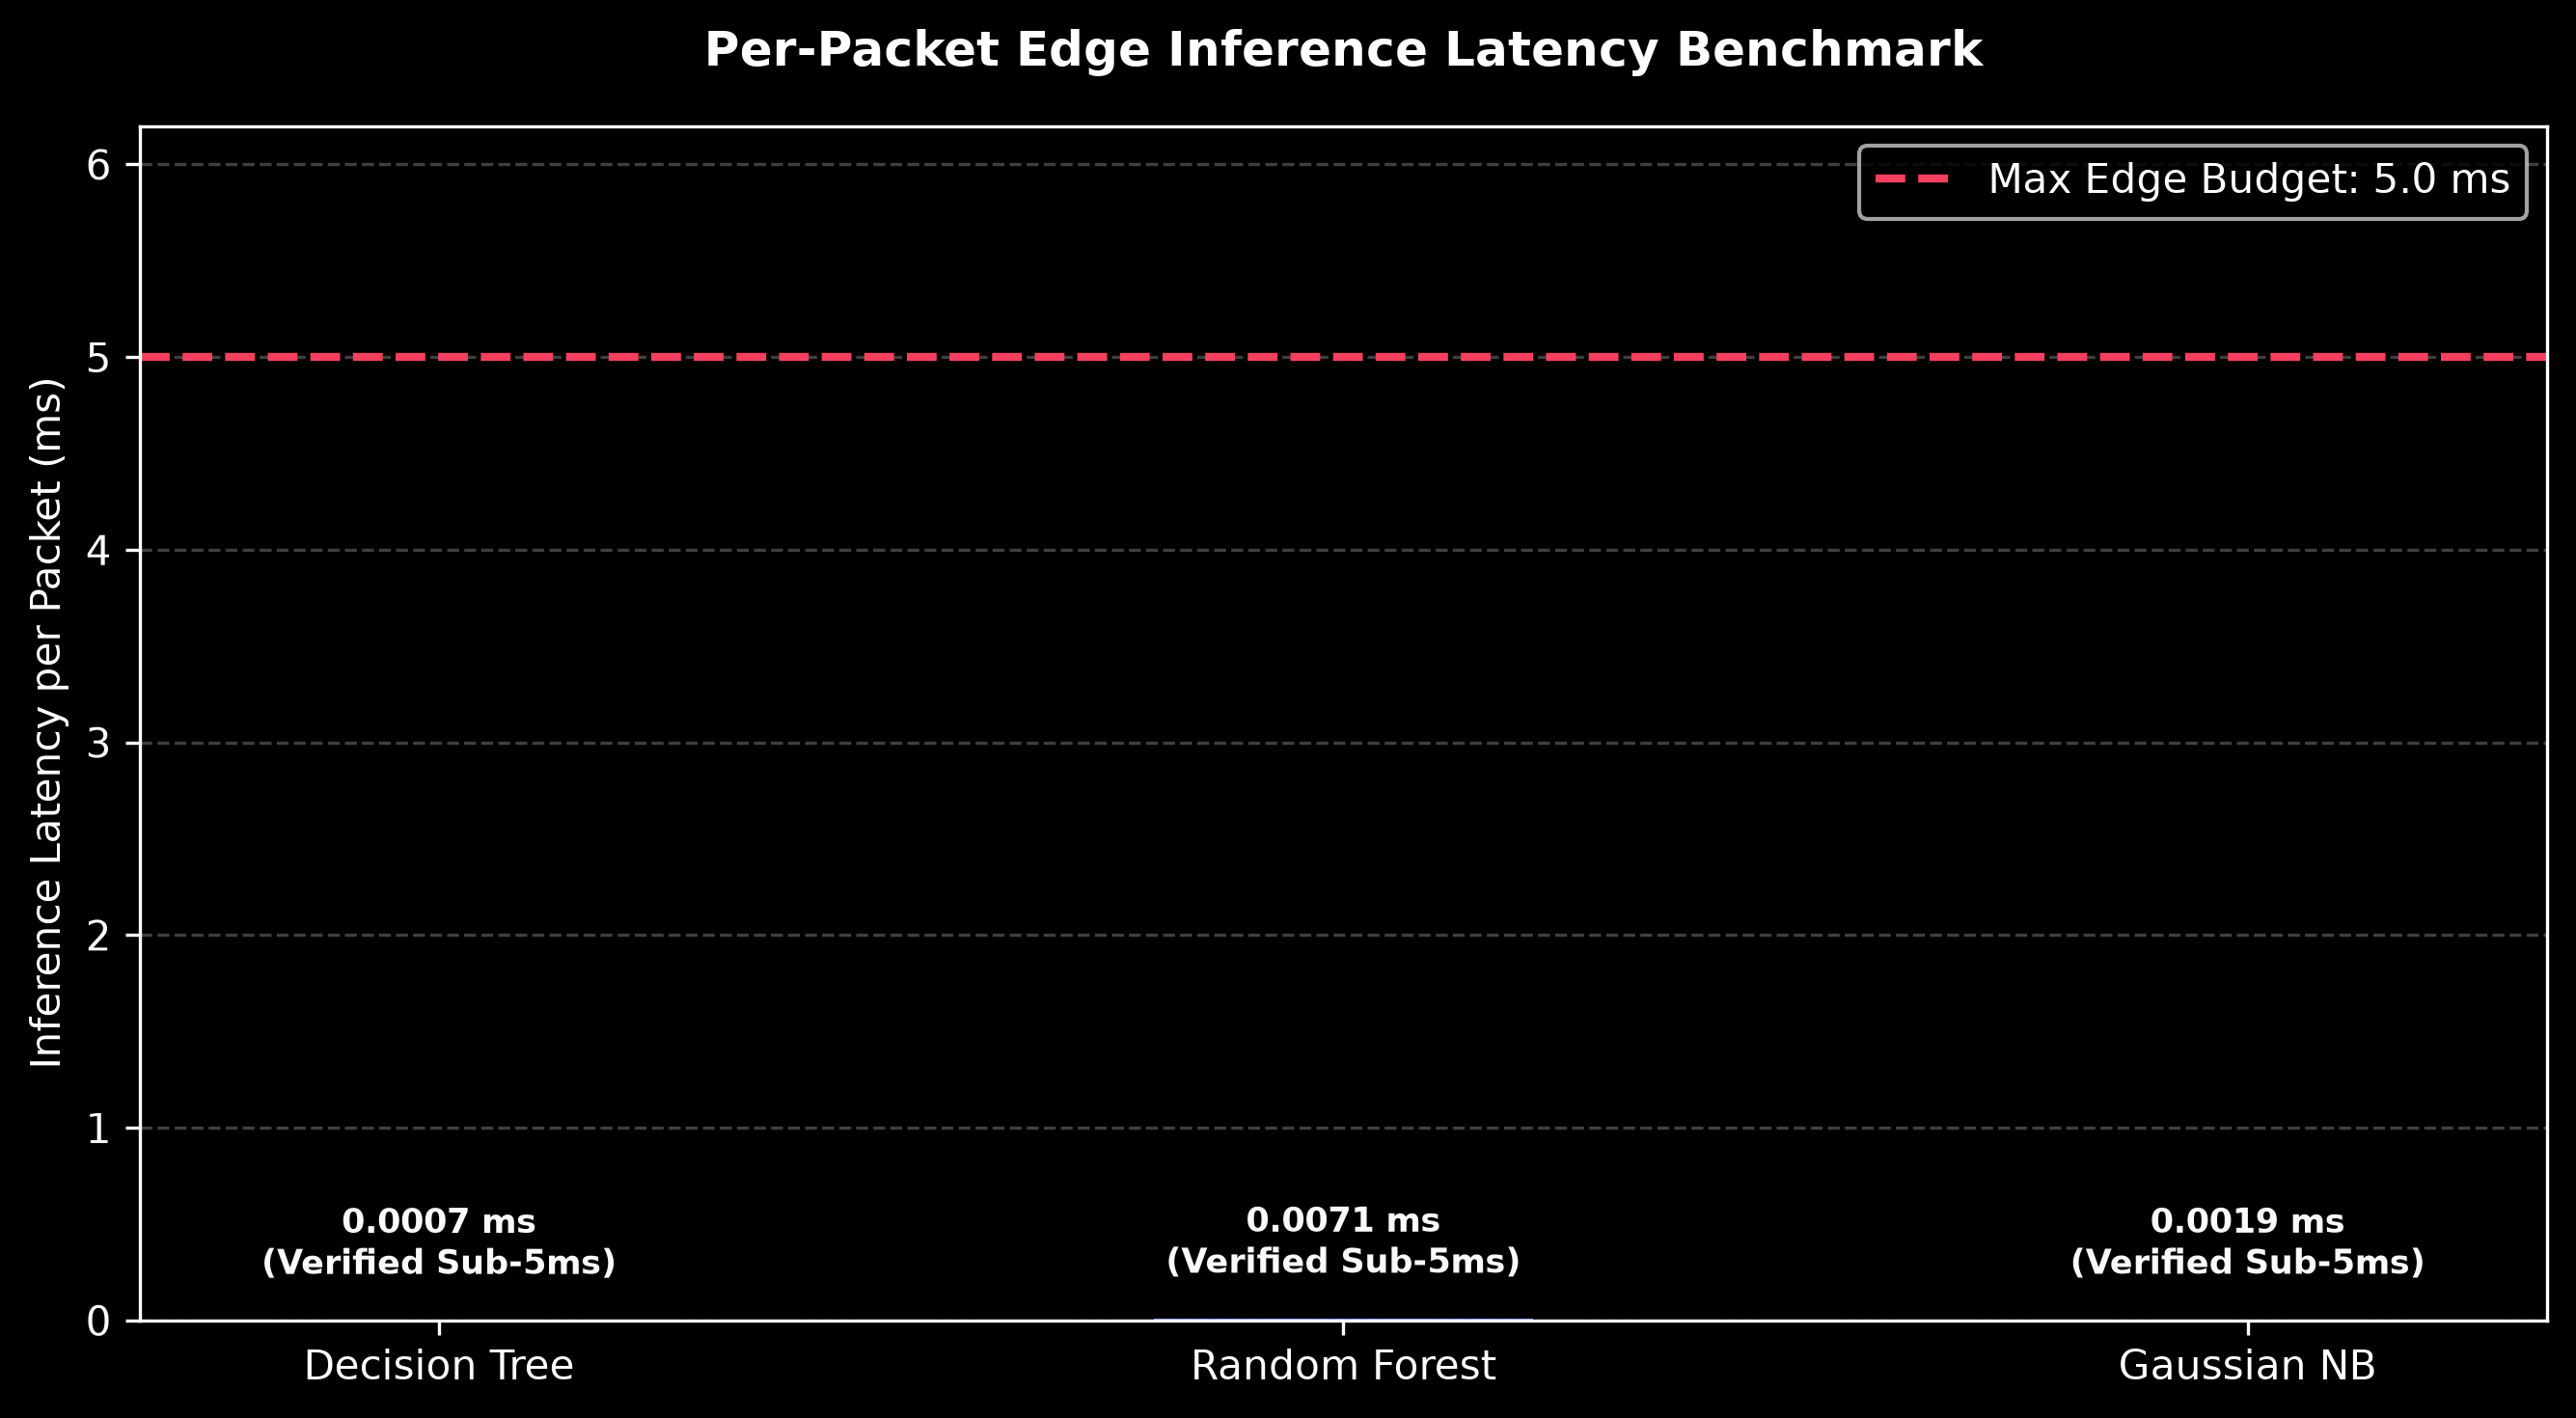

[✓] Saved visual: docs/diagrams/latency_benchmark.png


In [5]:
# Latency Ceiling Comparison Plot (Sub-5ms Proof)

fig, ax = plt.subplots(figsize=(9, 5), dpi=300)
bar_colors = ['#38bdf8', '#818cf8', '#34d399']
bars = ax.bar(results_df['Model'], results_df['Latency (ms)'], color=bar_colors, width=0.42)

# Max Edge Budget Ceiling Line
EDGE_BUDGET = 5.0
ax.axhline(EDGE_BUDGET, color='#f43f5e', linestyle='--', linewidth=2, label=f'Max Edge Budget: {EDGE_BUDGET} ms')

for bar in bars:
    y_val = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2.0,
        y_val + 0.18,
        f"{y_val:.4f} ms\n(Verified Sub-5ms)",
        ha='center',
        va='bottom',
        color='#f8fafc',
        fontweight='bold',
        fontsize=8.5
    )

ax.set_ylim(0, 6.2)
ax.set_title("Per-Packet Edge Inference Latency Benchmark", fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel("Inference Latency per Packet (ms)", fontsize=10)
ax.legend(loc='upper right', frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.25)
plt.tight_layout()

plt.savefig("../docs/diagrams/latency_benchmark.png", dpi=300)
plt.show()
print("[✓] Saved visual: docs/diagrams/latency_benchmark.png")